# SomnoScreen: analysis

A low-cost sleep-trouble risk screener built on NHANES 2017-18. This notebook only *reads* the saved results and calls the package in `src/somnoscreen/`, so it tells the story without re-running the long experiments.

**Target:** SLQ050, *"Have you ever told a doctor you had trouble sleeping?"*. It is self-reported, not a clinical diagnosis.

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from somnoscreen import config
from somnoscreen.data import load_dataset
from somnoscreen.features import FEATURE_NAMES, TARGET

R = config.RESULTS_DIR
pd.set_option('display.precision', 4)

## 1. Data

In [2]:
df = load_dataset()
print(f'{len(df):,} adults, {len(FEATURE_NAMES)} features')
print(df[TARGET].value_counts().rename({1: 'Yes', 0: 'No'}).to_string())
print(f'Positive rate: {df[TARGET].mean():.1%}')
df[FEATURE_NAMES].isna().mean().sort_values(ascending=False).head(6).rename('share missing')

5,824 adults, 19 features
sleep_trouble
No     4264
Yes    1560
Positive rate: 26.8%


phq_score       0.1300
systolic_bp     0.1130
diastolic_bp    0.1130
education       0.0987
snoring         0.0740
waist           0.0611
Name: share missing, dtype: float64

## 2. Phase 1: the thesis reproduces exactly

The original notebook logic was ported into the package and re-run. Every number is compared with the value saved in the original notebook.

In [3]:
check = pd.read_csv(R / 'reproduction_check.csv')
print(f"{int(check.Match.sum())} of {len(check)} numbers match; largest difference "
      f"{check.Abs_Diff.max():.4f}")
check.groupby('Section').Match.agg(['sum', 'count'])

275 of 275 numbers match; largest difference 0.0000


,sum,count
Section,,
Cluster sizes,4,4
Fairness,20,20
Paired bootstrap,84,84
Test-set comparison,167,167


## 3. Phase 2: imbalance strategies

Approach A, each model tuned on PR-AUC, then 5 folds x 5 repeats of stratified CV on the training set.

In [4]:
imb = pd.read_csv(R / 'phase2' / 'imbalance_cv_summary.csv')
summary = json.loads((R / 'phase2' / 'summary.json').read_text())
print('Chosen strategy:', summary['imbalance_strategy_chosen'])
print(pd.Series(summary['imbalance_strategy_mean_cv_pr_auc']).round(4).to_string())
imb.pivot(index='Model', columns='Imbalance', values='PR_AUC_mean')

Chosen strategy: class_weight
class_weight    0.5397
smote           0.5322
smotenc         0.5160


Imbalance,class_weight,smote,smotenc
Model,,,
Gradient Boosting,0.5437,0.5410,0.5220
KNN,NaN,0.4607,0.4464
LightGBM,0.5398,0.5428,0.5235
Logistic Regression,0.5472,0.5454,0.5267
Random Forest,0.5411,0.5243,0.5121
SVM,0.5232,0.4987,0.4882
XGBoost,0.5433,0.5410,0.5236


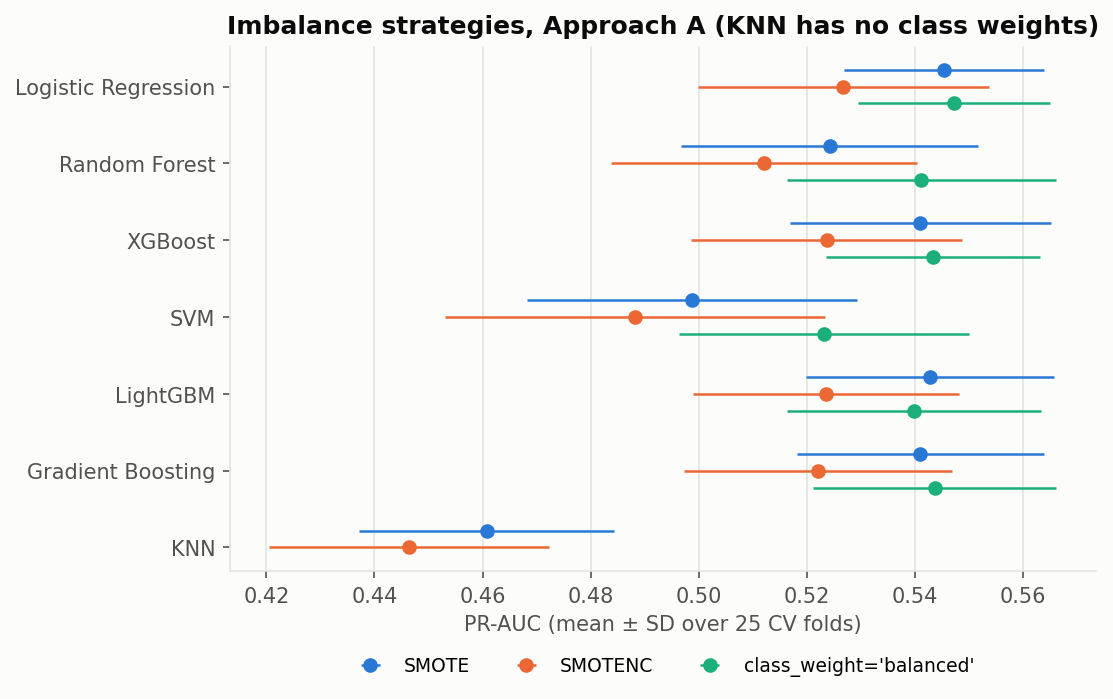

In [5]:
Image(str(config.FIGURES_DIR / 'imbalance_comparison.png'))

## 4. Does clustering help? (thesis question, new evaluation)

In [6]:
cv = pd.read_csv(R / 'phase2' / 'approach_cv_summary.csv')
cv.pivot(index='Model', columns='Approach', values=['ROC_AUC_mean', 'PR_AUC_mean'])

ROC_AUC_mean                 PR_AUC_mean                
Approach                       A       B       C           A       B       C
Model                                                                       
Gradient Boosting         0.7516  0.7513  0.7147      0.5437  0.5425  0.4889
KNN                       0.7033  0.7018  0.6611      0.4607  0.4596  0.4000
LightGBM                  0.7498  0.7492  0.7108      0.5398  0.5383  0.4835
Logistic Regression       0.7573  0.7572  0.7292      0.5472  0.5466  0.4970
Random Forest             0.7504  0.7494  0.7333      0.5411  0.5375  0.5165
SVM                       0.7510  0.7496  0.7410      0.5232  0.5238  0.5225
XGBoost                   0.7518  0.7520  0.7196      0.5433  0.5437  0.4935

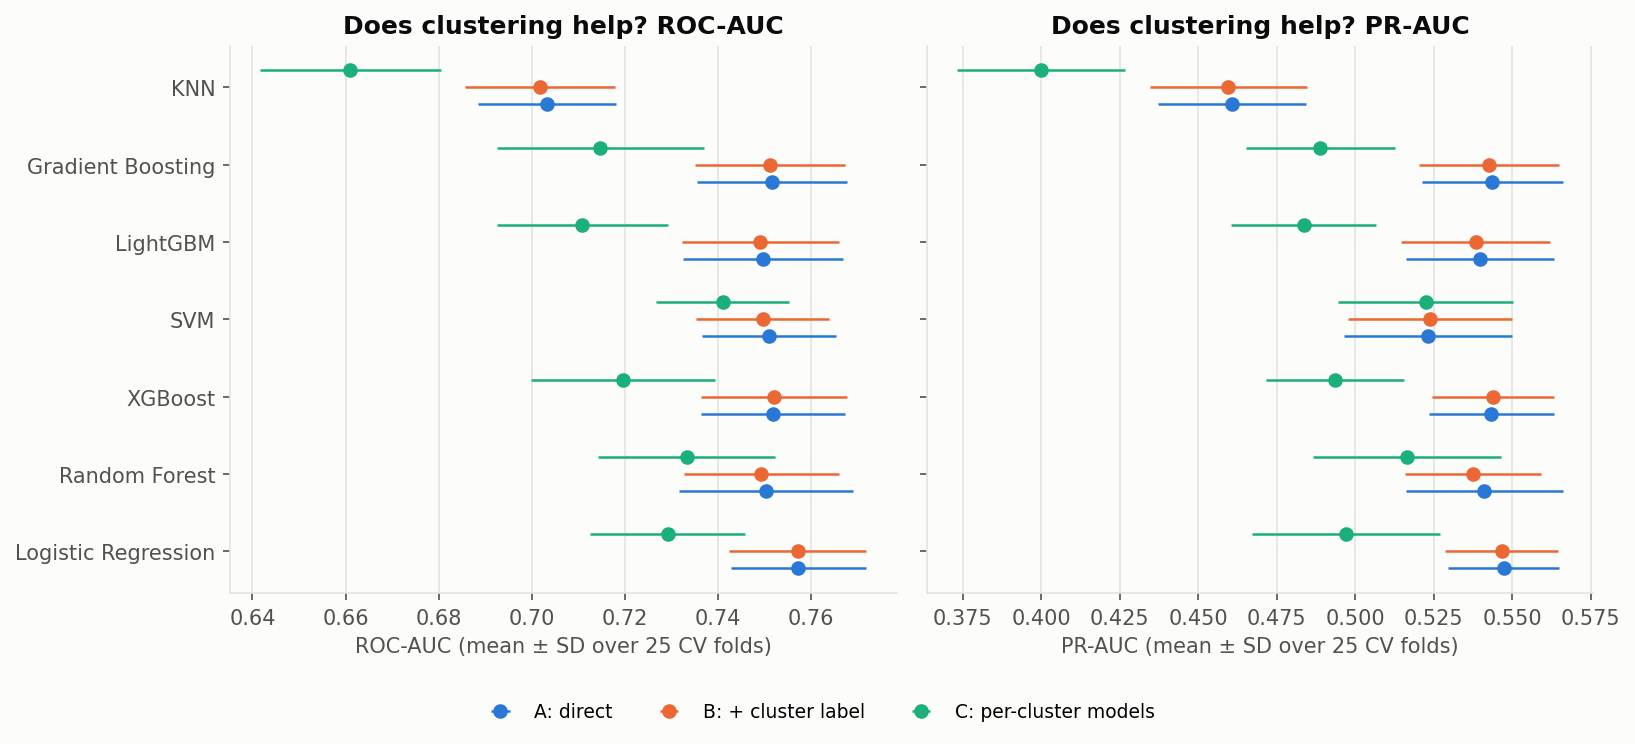

In [7]:
Image(str(config.FIGURES_DIR / 'approach_comparison.png'))

In [8]:
print('Corrected paired t-test on the 25 CV folds (count of 7 models):')
display(pd.DataFrame(summary['cv_corrected_ttest_counts']).T)
print('Paired bootstrap on the test set, 1,000 resamples (count of 7 models):')
pd.DataFrame(summary['test_bootstrap_counts']).T

Corrected paired t-test on the 25 CV folds (count of 7 models):


,better,worse,no clear difference
B vs A | PR_AUC,0,0,7
B vs A | ROC_AUC,0,0,7
C vs A | PR_AUC,0,6,1
C vs A | ROC_AUC,0,7,0


Paired bootstrap on the test set, 1,000 resamples (count of 7 models):


,better,worse,no clear difference
B vs A | PR_AUC,0,0,7
B vs A | ROC_AUC,0,0,7
C vs A | PR_AUC,0,5,2
C vs A | ROC_AUC,0,6,1


## 5. Final model: calibration, screening threshold, test set

In [9]:
ev = json.loads((R / 'final_model_evaluation.json').read_text())
sel = ev['selection']
print(f"Model: {sel['model']}, imbalance: {sel['imbalance_strategy']}, "
      f"calibration: {sel['calibration']}")
display(pd.read_csv(R / 'calibration_cv_summary.csv')[['Calibration', 'Brier_mean', 'Brier_std',
                                                     'ROC_AUC_mean', 'PR_AUC_mean']])
print(f"Screening threshold (target recall {ev['target_recall']}): "
      f"{ev['screening_threshold']:.4f}")
pd.read_csv(R / 'final_test_metrics.csv')

Model: Logistic Regression, imbalance: class_weight, calibration: sigmoid


,Calibration,Brier_mean,Brier_std,ROC_AUC_mean,PR_AUC_mean
0,none,0.1985,0.0048,0.7573,0.5472
1,sigmoid,0.1628,0.0035,0.7573,0.5472
2,isotonic,0.1632,0.0035,0.7559,0.5273


Screening threshold (target recall 0.7): 0.2462


,Model,Threshold,Accuracy,Balanced_Acc,Precision,Recall,F1,ROC_AUC,PR_AUC,Brier
0,Logistic Regression (final),0.2462,0.6695,0.6757,0.4274,0.6891,0.5276,0.7579,0.5300,0.1634
1,Majority class (flags nobody),1.0000,0.7322,0.5000,0.0000,0.0000,0.0000,0.5000,0.2678,0.1961


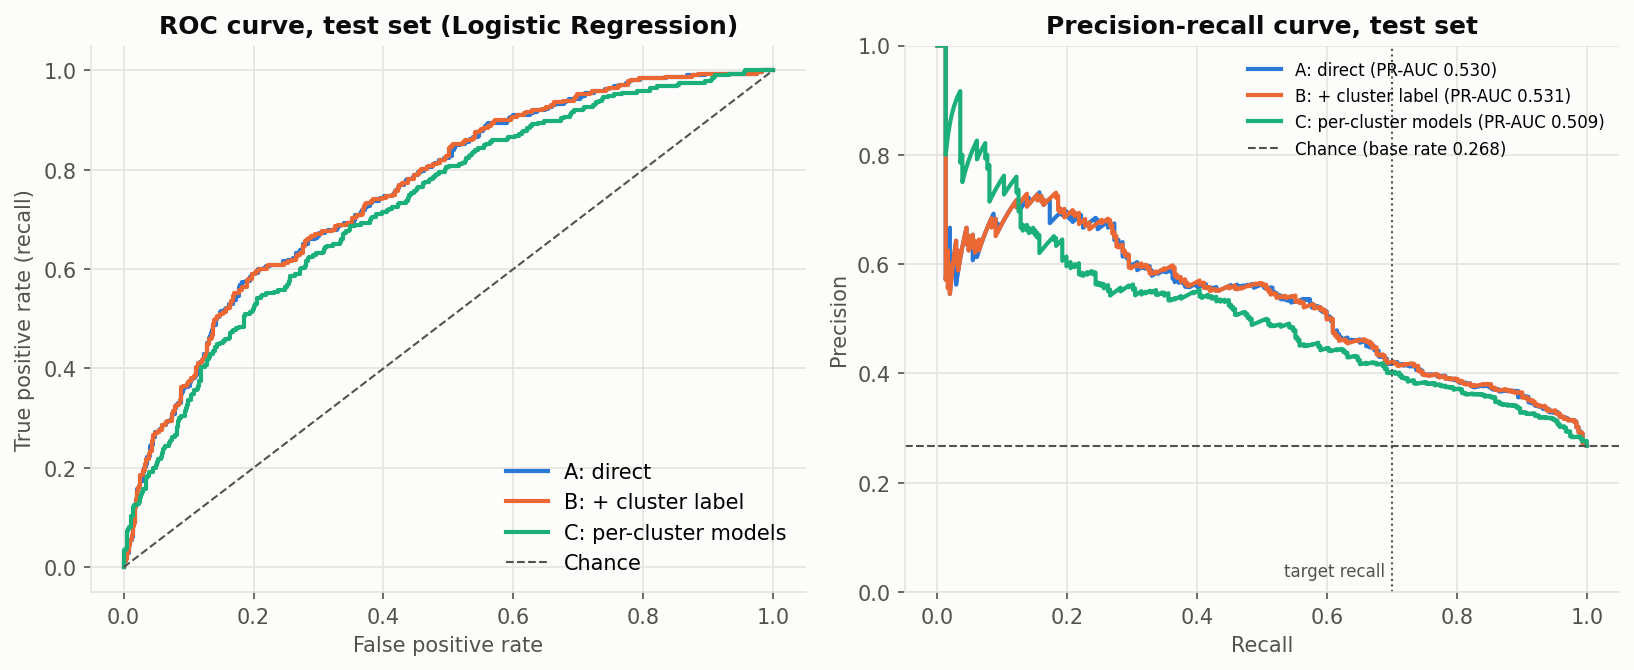

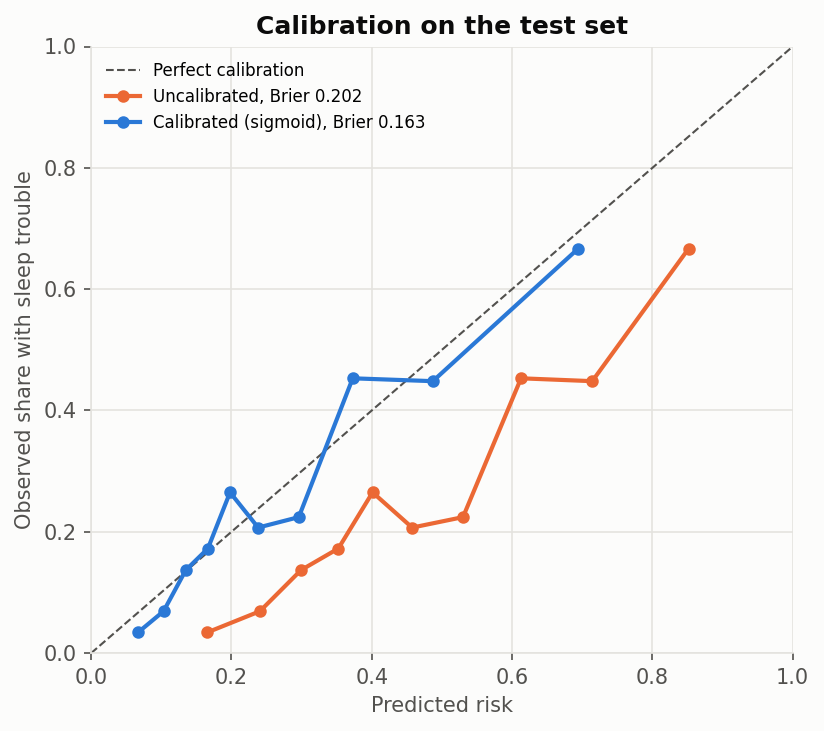

In [10]:
display(Image(str(config.FIGURES_DIR / 'roc_pr_curves.png')))
Image(str(config.FIGURES_DIR / 'calibration.png'))

## 6. Fairness at the screening threshold

,Group_Type,Group,N,Positive_Rate,Flagged_Rate,Accuracy,Precision,Recall,F1
0,Gender,Male,541,0.2403,0.3882,0.6895,0.4095,0.6615,0.5059
1,Gender,Female,624,0.2917,0.4696,0.6522,0.4403,0.7088,0.5432
2,Age,40 and above,724,0.3356,0.5456,0.6105,0.4506,0.7325,0.5580
3,Age,Under 40,441,0.1565,0.2449,0.7664,0.3426,0.5362,0.4181


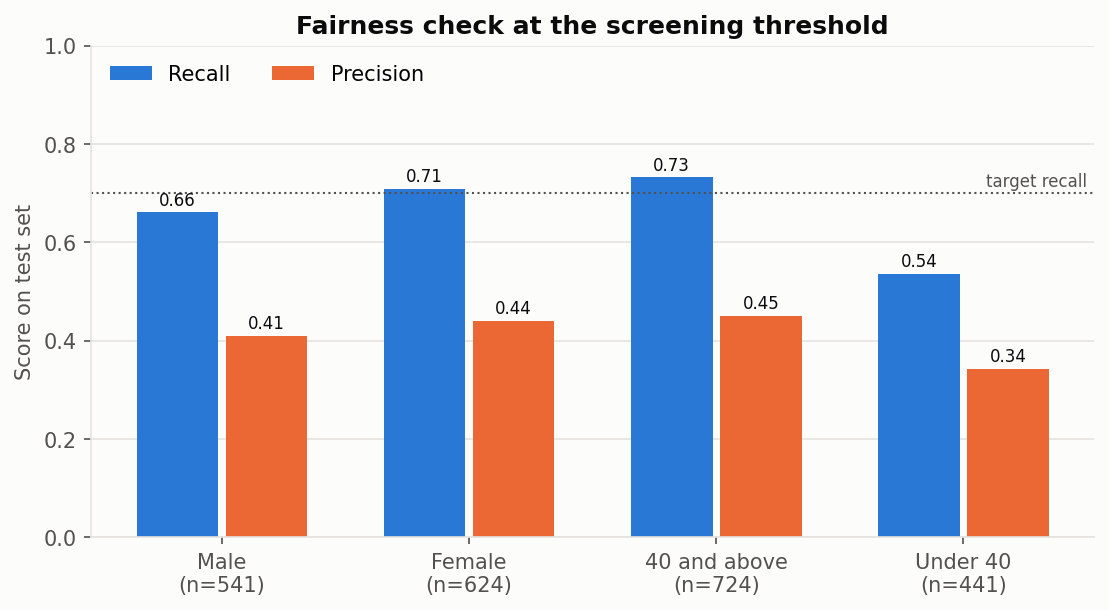

In [11]:
display(pd.read_csv(R / 'fairness.csv'))
Image(str(config.FIGURES_DIR / 'fairness.png'))

## 7. What drives the prediction (SHAP)

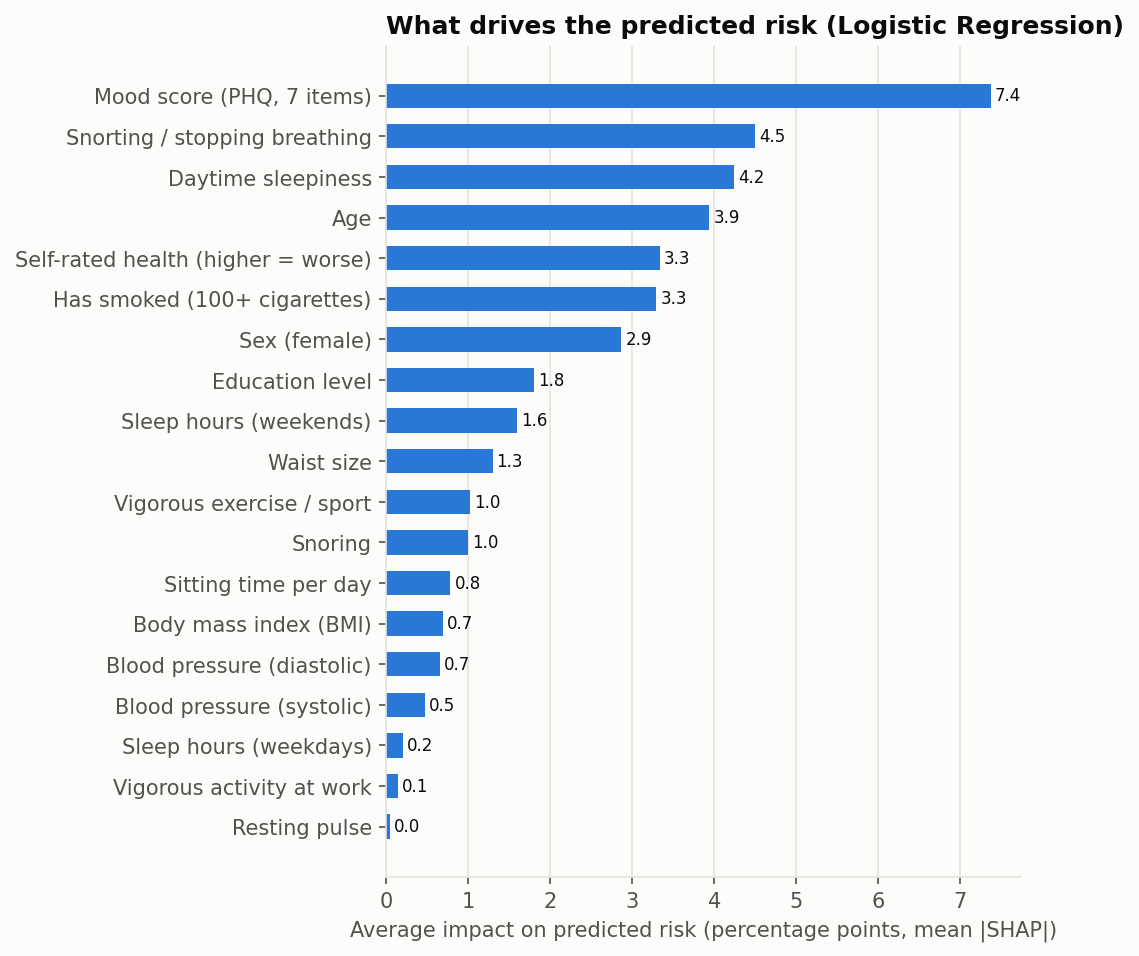

In [12]:
Image(str(config.FIGURES_DIR / 'shap_importance.png'))

One person, explained the same way the app does it (the deployed model, compared with the average person in the background sample):

In [13]:
import joblib
from somnoscreen.explain import explain_one, plot_contributions
model = joblib.load(config.MODEL_PATH)
background = pd.read_csv(config.SHAP_BACKGROUND_PATH)
person = df[FEATURE_NAMES].iloc[[0]]
contrib, avg = explain_one(model, background, person)
print(f'Predicted risk {model.predict_proba(person)[0, 1]:.1%} vs average {avg:.1%}')
plot_contributions(contrib, title='Why this estimate? (row 0)')

/opt/anaconda3/envs/somnoscreen/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Predicted risk 17.8% vs average 24.7%


<Figure size 700x540 with 1 Axes>

## Limitations

- The target is **self-reported** ("ever told a doctor"), not a diagnosed sleep disorder.
- NHANES **survey weights are not used**, so the numbers describe this sample, not the US population.
- **Cross-sectional** data: associations, not causes.
- **US population**, 2017-18 only; the model has not been validated elsewhere.